# Module 7C — Matplotlib Foundations (เลือกเรียน)

ส่วนนี้มีไว้สำหรับผู้ที่ต้องการเปิดโค้ด ตรวจ และแก้ figure ด้วยตนเอง ไม่ใช่เงื่อนไขก่อนเรียน Part A–B
code cell ซ่อนเป็นค่าเริ่มต้น แต่เปิดดูได้ทีละ cell

เลขหน้าใน citation เป็นหน้า PDF ดูรายละเอียด tag และขอบเขตการสกัดที่
[source map](module-07-data-visualization-source-map.md)

## Setup แบบ standalone

เซลล์ถัดไปตรวจและติดตั้ง core package ของ Module 7 ให้ครบใน kernel ปัจจุบัน
ไม่อาศัย environment จาก Part A, Part B หรือบทก่อนหน้า
รวมถึงเตรียมฟอนต์ Sarabun สำหรับข้อความในกราฟภาษาไทยให้อัตโนมัติ

## 1. สามชั้นที่ควรรู้จัก

- **Backend:** ส่งภาพไปยังหน้าจอ ไฟล์ PNG/PDF/SVG หรือ notebook
- **Artist:** ทุกสิ่งที่มองเห็น เช่น line, text, legend, axis และ patch
- **Scripting interface:** `pyplot` ช่วยสร้าง Figure/Axes และเรียก Artist ได้สะดวก

สำหรับงานวิจัยให้ใช้ object-oriented style เป็นหลัก: สร้าง `fig, ax = plt.subplots()` แล้วเรียก
`ax.plot()`, `ax.set_xlabel()` และ `fig.savefig()` เพราะควบคุมหลาย panel และแก้เฉพาะ axes ได้ชัดกว่า

> **ที่มาหลัก:** `[DV-NOTES, pdf pp. 77–88]`; `[RT1-DATAVIZ, pdf pp. 38–40]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

In [1]:
from importlib import invalidate_caches
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
import subprocess
import sys

try:
    from packaging.specifiers import SpecifierSet
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "packaging>=24,<27"])
    invalidate_caches()
    from packaging.specifiers import SpecifierSet

required = {
    "numpy": ">=1.26,<3", "pandas": ">=2.1,<3", "matplotlib": ">=3.8,<4",
    "seaborn": ">=0.13,<0.14", "plotly": ">=5.20,<8", "altair": ">=5.2,<7",
}
to_install = []
for distribution, constraint in required.items():
    try:
        installed = version(distribution)
    except PackageNotFoundError:
        installed = None
    if installed is None or installed not in SpecifierSet(constraint):
        to_install.append(f"{distribution}{constraint}")
if to_install:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--disable-pip-version-check",
        "--upgrade-strategy", "only-if-needed", *to_install,
    ])
    invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np

print("Python environment ready.")
print("Verified:", {name: version(name) for name in required})

Python environment ready.
Verified: {'numpy': '2.2.6', 'pandas': '2.3.3', 'matplotlib': '3.10.8', 'seaborn': '0.13.2', 'plotly': '7.0.0', 'altair': '6.2.2'}


In [2]:
# Prepare a verified Thai font for this kernel; no system-wide installation is needed.
import hashlib
from urllib.request import urlopen

import matplotlib as mpl
from matplotlib import font_manager
from matplotlib.ft2font import FT2Font

FONT_BASE_URL = "https://urban.cpe.ku.ac.th/ai-for-research/downloads/fonts/"
FONT_SPECS = {
    "Sarabun-Regular.ttf": "226d4f368fbc0457990ddef2692679badfd2c1a4e89e5ac4d43c10ba7743b2f1",
    "Sarabun-Bold.ttf": "d38308ca27d067b9a1b79006337c1f9a66c29aa016d96a9d88d3801da7fa83b9",
}
FONT_DIRS = [
    Path("fonts"),
    Path("../fonts"),
    Path("course-materials/module-07/fonts"),
    Path.home() / ".cache" / "ai-for-research" / "module-07" / "fonts",
]

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def verified_font_path(filename, expected_sha256):
    for directory in FONT_DIRS:
        candidate = directory / filename
        if candidate.is_file() and sha256_file(candidate) == expected_sha256:
            return candidate

    target_dir = FONT_DIRS[-1]
    target_dir.mkdir(parents=True, exist_ok=True)
    target = target_dir / filename
    temporary = target.with_suffix(target.suffix + ".download")
    try:
        with urlopen(FONT_BASE_URL + filename, timeout=30) as response:
            if not response.geturl().startswith(FONT_BASE_URL):
                raise RuntimeError("Thai-font download left the approved course URL.")
            content = response.read(2 * 1024 * 1024 + 1)
        if len(content) > 2 * 1024 * 1024 or hashlib.sha256(content).hexdigest() != expected_sha256:
            raise RuntimeError("Thai-font download failed verification.")
        temporary.write_bytes(content)
        temporary.replace(target)
    finally:
        temporary.unlink(missing_ok=True)
    return target

font_paths = [verified_font_path(name, digest) for name, digest in FONT_SPECS.items()]
for font_path in font_paths:
    font_manager.fontManager.addfont(font_path)

font_name = font_manager.FontProperties(fname=str(font_paths[0])).get_name()
if font_name != "Sarabun":
    raise RuntimeError(f"Unexpected Thai font family: {font_name}")

thai_glyph_probe = (
    "กขฃคฅฆงจฉชซฌญฎฏฐฑฒณดตถทธนบปผฝพฟภมยรลวศษสหฬอฮ"
    "ะาำิีึืุูเแโใไๅๆฯ่้๊๋์ํ๐๑๒๓๔๕๖๗๘๙"
)
for font_path in font_paths:
    charmap = FT2Font(str(font_path)).get_charmap()
    missing = [character for character in thai_glyph_probe if ord(character) not in charmap]
    if missing:
        raise RuntimeError(f"Sarabun is missing required Thai glyphs: {missing}")

fallback_path = Path(font_manager.findfont(
    font_manager.FontProperties(family="DejaVu Sans"), fallback_to_default=False
))
combined_charmap = set().union(
    *(set(FT2Font(str(path)).get_charmap()) for path in [font_paths[0], fallback_path])
)
symbol_glyph_probe = "−–—•±×÷≤≥≈°℃µαβγΔ→←↔∞√"
missing_symbols = [character for character in symbol_glyph_probe if ord(character) not in combined_charmap]
if missing_symbols:
    raise RuntimeError(f"Font stack is missing required scientific glyphs: {missing_symbols}")

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Sarabun", "DejaVu Sans"],
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.unicode_minus": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})
print("Thai font ready: Sarabun")

Thai font ready: Sarabun


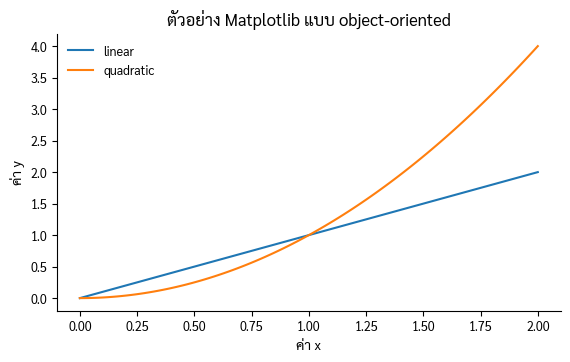

In [3]:
x = np.linspace(0, 2, 100)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(x, x, label="linear")
ax.plot(x, x**2, label="quadratic")
ax.set(xlabel="ค่า x", ylabel="ค่า y", title="ตัวอย่าง Matplotlib แบบ object-oriented")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 2. Anatomy ของ figure

**Figure** คือพื้นที่ทั้งภาพ, **Axes** คือหนึ่ง plot พร้อมระบบพิกัด, **Axis** คือแกน x/y พร้อม tick และ label
และสิ่งที่วาดทั้งหมดเป็น Artist ตัวอย่างต่อไปติดป้ายส่วนสำคัญเพื่อให้ค้นตำแหน่งแก้กราฟได้

> **ที่มาหลัก:** `[DV-NOTES, pdf pp. 77–88]`; `[RT1-DATAVIZ, pdf p. 41]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

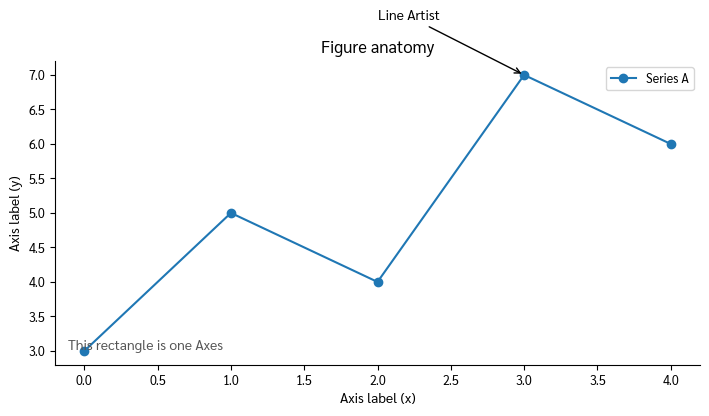

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 4.3))
x = np.arange(5); y = np.array([3, 5, 4, 7, 6])
line, = ax.plot(x, y, marker="o", label="Series A")
ax.set(title="Figure anatomy", xlabel="Axis label (x)", ylabel="Axis label (y)")
legend = ax.legend(frameon=True)
ax.annotate("Line Artist", xy=(3, 7), xytext=(2.0, 7.8), arrowprops={"arrowstyle":"->"})
ax.text(.02, .05, "This rectangle is one Axes", transform=ax.transAxes, color="#555")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

## 3. เมื่อใดต้องเปิดโค้ด

เปิดโค้ดเมื่อจำเป็นต้องตรวจ aggregation, เปลี่ยน scale/units, แก้ clipping, กำหนดขนาดจริง หรือส่งออกไฟล์
ไม่จำเป็นต้องเปิดเพียงเพื่อเปลี่ยนสีตามใจ หากยังอธิบาย Chart Contract และข้อค้นพบไม่ได้

> **ที่มาหลัก:** แนวทางบทเรียนสังเคราะห์จาก `[RT1-DATAVIZ, pdf pp. 38–50]` และ workflow ของ Module 7 ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน